# Clasificación de Fashion-MNIST - TensorFlow

Versión de referencia para el anexo: misma red densa, validación, detención temprana y análisis por clase que el notebook principal de PyTorch.

## Dependencias

En un entorno nuevo: `%pip install tensorflow numpy matplotlib scikit-learn`. La primera carga de Fashion-MNIST descarga el dataset.

Este notebook debe ejecutarse con el kernel **Python 3 (IPD434)**. TensorFlow es la alternativa del anexo; la implementación principal de la clase está en `04_clasificacion_fashion_mnist_pytorch.ipynb`.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

2026-09-29 00:14:29.071307: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-09-29 00:14:29.136865: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-09-29 00:14:30.952674: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
(x_train_all, y_train_all), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()
x_train_all = x_train_all.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_train, x_val = x_train_all[:-6000], x_train_all[-6000:]
y_train, y_val = y_train_all[:-6000], y_train_all[-6000:]
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]
print(x_train.shape, x_val.shape, x_test.shape)

(54000, 28, 28) (6000, 28, 28) (10000, 28, 28)


La prueba queda aislada. En un proyecto real se debe justificar que las particiones representan el escenario de despliegue.

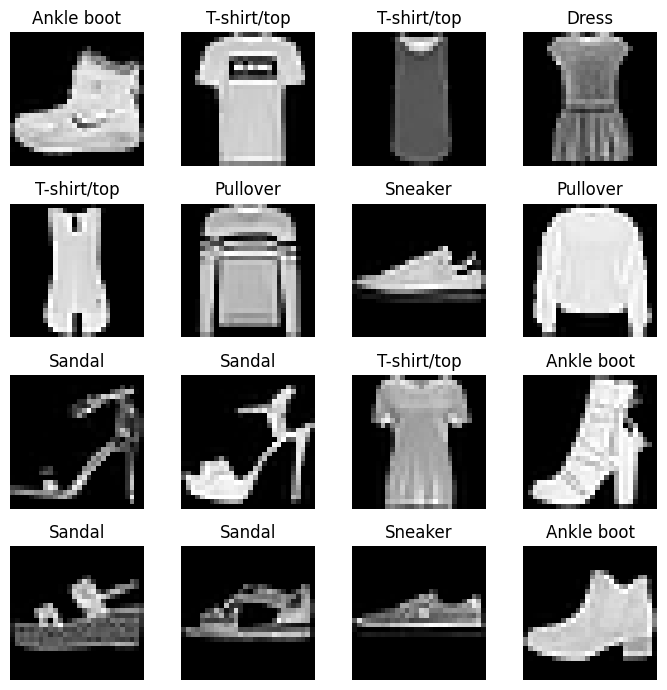

In [3]:
fig, axes = plt.subplots(4, 4, figsize=(7, 7))
for ax, image, label in zip(axes.ravel(), x_train[:16], y_train[:16]):
    ax.imshow(image, cmap='gray')
    ax.set_title(class_names[label])
    ax.axis('off')
plt.tight_layout()
plt.show()

In [4]:
model = keras.Sequential([
    keras.layers.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dropout(0.25),
    keras.layers.Dense(10),
])
model.compile(
    optimizer='adam',
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy'],
)
model.summary()

I0000 00:00:1790651673.695633 1498885 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3848 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=3, restore_best_weights=True
)
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=30, batch_size=128, callbacks=[early_stop], verbose=2,
)

Epoch 1/30


2026-09-29 00:14:35.462122: I external/local_xla/xla/service/service.cc:163] XLA service 0x7f04500050c0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-09-29 00:14:35.462143: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA GeForce RTX 3060 Laptop GPU, Compute Capability 8.6
2026-09-29 00:14:35.490017: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-09-29 00:14:35.605508: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900
2026-09-29 00:14:36.193521: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_96', 4 bytes spill stores, 4 bytes spill loads

I0000 00:00:1790651677.877677 1499036 device_compiler.h:196] Compiled cluster using XLA!  This line is l

422/422 - 7s - 18ms/step - accuracy: 0.7869 - loss: 0.6164 - val_accuracy: 0.8495 - val_loss: 0.4242
Epoch 2/30
422/422 - 1s - 2ms/step - accuracy: 0.8486 - loss: 0.4335 - val_accuracy: 0.8607 - val_loss: 0.3831
Epoch 3/30
422/422 - 1s - 2ms/step - accuracy: 0.8609 - loss: 0.3936 - val_accuracy: 0.8670 - val_loss: 0.3580
Epoch 4/30
422/422 - 1s - 2ms/step - accuracy: 0.8702 - loss: 0.3649 - val_accuracy: 0.8728 - val_loss: 0.3412
Epoch 5/30
422/422 - 1s - 2ms/step - accuracy: 0.8755 - loss: 0.3490 - val_accuracy: 0.8768 - val_loss: 0.3382
Epoch 6/30
422/422 - 1s - 2ms/step - accuracy: 0.8791 - loss: 0.3360 - val_accuracy: 0.8782 - val_loss: 0.3282
Epoch 7/30
422/422 - 1s - 2ms/step - accuracy: 0.8841 - loss: 0.3226 - val_accuracy: 0.8783 - val_loss: 0.3240
Epoch 8/30
422/422 - 1s - 2ms/step - accuracy: 0.8836 - loss: 0.3165 - val_accuracy: 0.8792 - val_loss: 0.3213
Epoch 9/30
422/422 - 1s - 2ms/step - accuracy: 0.8878 - loss: 0.3074 - val_accuracy: 0.8812 - val_loss: 0.3145
Epoch 10/30

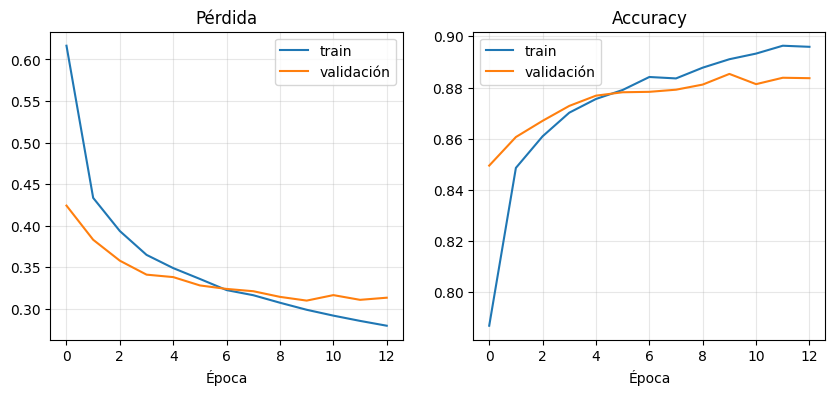

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history.history['loss'], label='train')
axes[0].plot(history.history['val_loss'], label='validación')
axes[0].set(title='Pérdida', xlabel='Época')
axes[1].plot(history.history['accuracy'], label='train')
axes[1].plot(history.history['val_accuracy'], label='validación')
axes[1].set(title='Accuracy', xlabel='Época')
for ax in axes:
    ax.legend(); ax.grid(alpha=0.3)
plt.show()

## Evaluación final

La prueba se usa después de fijar arquitectura, optimizador y punto de detención. Las predicciones se obtienen a partir de los logits mediante `argmax`; no es necesario calcular `softmax` para decidir la clase.

In [7]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
logits = model.predict(x_test, verbose=0)
y_pred = np.argmax(logits, axis=1)
print(f'loss={test_loss:.4f}, accuracy={test_accuracy:.4f}')
print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

2026-09-29 00:14:52.770830: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_34', 20 bytes spill stores, 20 bytes spill loads



loss=0.3398, accuracy=0.8808
              precision    recall  f1-score   support

 T-shirt/top      0.853     0.825     0.839      1000
     Trouser      0.983     0.973     0.978      1000
    Pullover      0.781     0.805     0.793      1000
       Dress      0.862     0.901     0.881      1000
        Coat      0.762     0.832     0.795      1000
      Sandal      0.971     0.957     0.964      1000
       Shirt      0.723     0.642     0.680      1000
     Sneaker      0.937     0.951     0.944      1000
         Bag      0.982     0.962     0.972      1000
  Ankle boot      0.954     0.960     0.957      1000

    accuracy                          0.881     10000
   macro avg      0.881     0.881     0.880     10000
weighted avg      0.881     0.881     0.880     10000



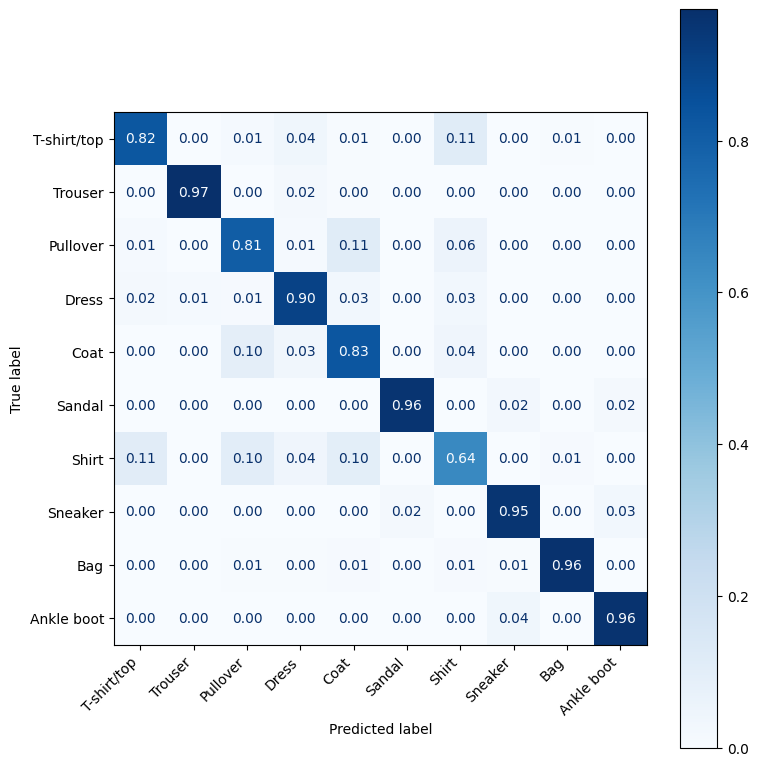

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=class_names, normalize='true',
    values_format='.2f', cmap='Blues', ax=ax
)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()